# **자연어 처리(NLP : natural language processing)**

* 기계에게 인간의 언어를 이해시키기 위한 모든 처리 
*  음성 인식, 내용 요약, 번역, 사용자의 감성 분석, 텍스트 분류 작업, 질의 응답 시스템, 챗봇

In [1]:
import os

import warnings
warnings.filterwarnings(action='ignore')

# TensorFlow 안내 및 경고 로그 끄기 (3 = ERROR/FATAL 로그만 표시)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# oneDNN 최적화 관련 안내 문구 숨기기
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

# absl 라이브러리 초기화 전 경고(WARNING: All log messages...) 숨기기
os.environ['ABSL_LOGGING_MIN_LOG_LEVEL'] = '3'

# 이후에 TensorFlow 임포트
import tensorflow as tf

# **[2] 텍스트 전처리(Text preprocessing)**

In [2]:
# pip install nltk

## **토큰화(Tokenization)**
* 주어진 코퍼스(corpus)에서 토큰(token) 단위로 잘라내는 작업
* <font color=red><b>영어 : nltk
* <font color=red><b>한국어 : konlpy, mecab

### 단어 
* <font color=red><b>word_tokenize , text_to_word_sequence

In [3]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [4]:
from nltk.tokenize import word_tokenize
from nltk.tokenize import WordPunctTokenizer
from tensorflow.keras.preprocessing.text import text_to_word_sequence

In [5]:
print('단어 토큰화1 :',word_tokenize("Don't be fooled by the dark sounding name, Mr. Jone's Orphanage is as cheery as cheery goes for a pastry shop."))

단어 토큰화1 : ['Do', "n't", 'be', 'fooled', 'by', 'the', 'dark', 'sounding', 'name', ',', 'Mr.', 'Jone', "'s", 'Orphanage', 'is', 'as', 'cheery', 'as', 'cheery', 'goes', 'for', 'a', 'pastry', 'shop', '.']


In [6]:
print('단어 토큰화2 :',WordPunctTokenizer().tokenize("Don't be fooled by the dark sounding name, Mr. Jone's Orphanage is as cheery as cheery goes for a pastry shop."))

단어 토큰화2 : ['Don', "'", 't', 'be', 'fooled', 'by', 'the', 'dark', 'sounding', 'name', ',', 'Mr', '.', 'Jone', "'", 's', 'Orphanage', 'is', 'as', 'cheery', 'as', 'cheery', 'goes', 'for', 'a', 'pastry', 'shop', '.']


In [7]:
print('단어 토큰화3 :',text_to_word_sequence("Don't be fooled by the dark sounding name, Mr. Jone's Orphanage is as cheery as cheery goes for a pastry shop."))

단어 토큰화3 : ["don't", 'be', 'fooled', 'by', 'the', 'dark', 'sounding', 'name', 'mr', "jone's", 'orphanage', 'is', 'as', 'cheery', 'as', 'cheery', 'goes', 'for', 'a', 'pastry', 'shop']


### 문장
* <font color=red><b>sent_tokenize

In [8]:
from nltk.tokenize import sent_tokenize

text = """Mr.Kim His barber kept his word 192.168.0.1.     But keeping such
crazy.     Finally, the barber went up to the cliff.    He dug some reeds. He looked 
about, to make near."""
print('문장 토큰화1 :',sent_tokenize(text))

문장 토큰화1 : ['Mr.Kim His barber kept his word 192.168.0.1.', 'But keeping such\ncrazy.', 'Finally, the barber went up to the cliff.', 'He dug some reeds.', 'He looked \nabout, to make near.']


In [9]:
from nltk.tokenize import sent_tokenize

text = """Mr.Kim 이것은 사과이다 192.168.0.1.     오늘은 비가 안온다. 딥러닝을 베운다."""
print('문장 토큰화1 :',sent_tokenize(text))

문장 토큰화1 : ['Mr.Kim 이것은 사과이다 192.168.0.1.', '오늘은 비가 안온다.', '딥러닝을 베운다.']


###  품사

In [10]:
import nltk
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [11]:
from nltk.tokenize import word_tokenize
from nltk.tag import pos_tag

text = "I am actively looking for Ph.D. students. and you are a Ph.D. student."
#text = "파랗고 파란 Mr.Kim. 하늘은. 참 예쁘다."
tokenized_sentence = word_tokenize(text)

print('---단어 토큰화 :',tokenized_sentence)
print('---품사 태깅 :',pos_tag(tokenized_sentence))

---단어 토큰화 : ['I', 'am', 'actively', 'looking', 'for', 'Ph.D.', 'students', '.', 'and', 'you', 'are', 'a', 'Ph.D.', 'student', '.']
---품사 태깅 : [('I', 'PRP'), ('am', 'VBP'), ('actively', 'RB'), ('looking', 'VBG'), ('for', 'IN'), ('Ph.D.', 'NNP'), ('students', 'NNS'), ('.', '.'), ('and', 'CC'), ('you', 'PRP'), ('are', 'VBP'), ('a', 'DT'), ('Ph.D.', 'NNP'), ('student', 'NN'), ('.', '.')]


### 한국어 전용
* pip install jpype1
* pip install konlpy
    * Okt(Twitter), KKomo, Komoran, Hannanum,  (+Mecab)
* pip install mecab-python3

<pre> <b>JDK21 설치</b>
    * PowerShell 관리자 권한 실행
    * docker exec -it -u root my_tf_env bash
    * apt-get update && apt-get install -y openjdk-21-jdk
    * java -version
    * readlink -f $(which java)  
        * 설치위치 : /usr/lib/jvm/java-21-openjdk-amd64/bin/java
    * export JAVA_HOME=/usr/lib/jvm/java-21-openjdk-amd64
    * export PATH=$PATH:$JAVA_HOME/bin

<pre> <b>Mecab설치</b>
    * 주피터 터미널에서 실행
    * pip install mecab-python3 mecab-ko-dic

    * 파워쉘 관리자권한 실행
    * docker exec -it -u root my_tf_env bash
    * mkdir -p /usr/local/etc
    * echo "dicdir=/usr/local/lib/python3.12/site-packages/mecab_ko_dic" > /usr/local/etc/mecabrc
    * cat /usr/local/etc/mecabrc
        ---> dicdir=/usr/local/lib/python3.12/site-packages/mecab_ko_dic
    

<pre>
# pip install mecab-python3 mecab-ko-dic
Requirement already satisfied: mecab-python3 in /usr/local/lib/python3.12/site-packages (1.0.12)
Collecting mecab-ko-dic
  Downloading mecab-ko-dic-1.0.0.tar.gz (33.2 MB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.2/33.2 MB 10.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Building wheels for collected packages: mecab-ko-dic
  Building wheel for mecab-ko-dic (setup.py) ... done
  Created wheel for mecab-ko-dic: filename=mecab_ko_dic-1.0.0-py3-none-any.whl size=33424436 sha256=3da488600b4316683ab1ae3523c13084d8beea25952f4b8a8b29476d4bcde4ed
  Stored in directory: /root/.cache/pip/wheels/38/b6/bb/e5c73805f8318db251a0a10b4a8becfb4c4e9e49a5b892761a
Successfully built mecab-ko-dic
Installing collected packages: mecab-ko-dic
Successfully installed mecab-ko-dic-1.0.0
WARNING: Running pip as the 'root' user can result in broken permissions and conflicting behaviour with the system package manager, possibly rendering your system unusable. It is recommended to use a virtual environment instead: https://pip.pypa.io/warnings/venv. Use the --root-user-action option if you know what you are doing and want to suppress this warning.

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
# 

In [12]:
!java -version

openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-deb13u1-Debian)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-deb13u1-Debian, mixed mode, sharing)


In [13]:
from konlpy.tag import Okt
from konlpy.tag import Kkma
from konlpy.tag import Komoran

okt     = Okt()
kkma    = Kkma()
komoran = Komoran()

print(komoran.morphs("아버지가방에들어가신다"))
print(komoran.pos("아버지가방에들어가신다"))
print(komoran.nouns("아버지가방에들어가신다"))

print('OKT 형태소 분석 :',okt.morphs("열심히 코딩한 당신. 연휴에는 여행을 가봐요."))
print('OKT 품사 태깅 :'  ,okt.pos   ("열심히 코딩한 당신, 연휴에는 여행을 가봐요"))
print('OKT 명사 추출 :'  ,okt.nouns ("열심히 코딩한 당신, 연휴에는 여행을 가봐요")) 

['아버지', '가방', '에', '들어가', '시', 'ㄴ다']
[('아버지', 'NNG'), ('가방', 'NNP'), ('에', 'JKB'), ('들어가', 'VV'), ('시', 'EP'), ('ㄴ다', 'EC')]
['아버지', '가방']
OKT 형태소 분석 : ['열심히', '코딩', '한', '당신', ',', '연휴', '에는', '여행', '을', '가봐요']
OKT 품사 태깅 : [('열심히', 'Adverb'), ('코딩', 'Noun'), ('한', 'Josa'), ('당신', 'Noun'), (',', 'Punctuation'), ('연휴', 'Noun'), ('에는', 'Josa'), ('여행', 'Noun'), ('을', 'Josa'), ('가봐요', 'Verb')]
OKT 명사 추출 : ['코딩', '당신', '연휴', '여행']


In [14]:
# import MeCab
# import mecab_ko_dic

# # 패키지가 내장한 시스템 사전 경로 상수를 직접 지정
# tagger = MeCab.Tagger(f"-d {mecab_ko_dic.DICDIR}")
# print(tagger.parse("아버지가방에들어가신다"))


* <font color=red><b>사전 위치 확인</b>

In [15]:
import os
from konlpy.tag import Mecab
import mecab_ko_dic

# 1. 패키지의 실제 루트 경로를 리스트에서 문자열로 가져옵니다.
package_root = list(mecab_ko_dic.__path__)[0]
# 2. 패키지 루트 안에서 'dicrc' 설정 파일이 들어있는 진짜 사전 경로를 탐색합니다.
if os.path.exists(os.path.join(package_root, 'dicrc')):
    real_dicpath = package_root
elif os.path.exists(os.path.join(package_root, 'dictionary', 'dicrc')):
    real_dicpath = os.path.join(package_root, 'dictionary')
else:
    # 혹시 다른 하위 폴더에 들어있는지 전부 뒤져서 'dicrc'가 있는 폴더를 찾습니다.
    real_dicpath = None
    for root, dirs, files in os.walk(package_root):
        if 'dicrc' in files:
            real_dicpath = root
            break

# 3. 찾은 정확한 사전 경로를 출력하여 확인하고 Mecab에 주입합니다.
if real_dicpath:
    print(f"[알림] 찾은 진짜 사전 경로: {real_dicpath}")
    mecab = Mecab(dicpath="/usr/local/lib/python3.12/site-packages/mecab_ko_dic/dicdir")
else:
    raise FileNotFoundError("mecab-ko-dic 패키지 내부에서 사전 설정(dicrc) 파일을 찾을 수 없습니다.")

[알림] 찾은 진짜 사전 경로: /usr/local/lib/python3.12/site-packages/mecab_ko_dic/dicdir


In [16]:
import os
from konlpy.tag import Mecab
import mecab_ko_dic

mecab = Mecab(dicpath="/usr/local/lib/python3.12/site-packages/mecab_ko_dic/dicdir")
#mecab = Mecab()

# 4. 분석 결과 출
print('Mecab 형태소 분석 :', mecab.morphs("열심히 코딩한 당신, 연휴에는 여행을 가봐요"))
print('Mecab 품사 태깅 :', mecab.pos("열심히 코딩한 당신, 연휴에는 여행을 가봐요"))
print('Mecab 명사 추출 :', mecab.nouns("열심히 코딩한 당신, 연휴에는 여행을 가봐요"))

Mecab 형태소 분석 : ['열심히', '코딩', '한', '당신', ',', '연휴', '에', '는', '여행', '을', '가', '봐요']
Mecab 품사 태깅 : [('열심히', 'MAG'), ('코딩', 'NNG'), ('한', 'XSA+ETM'), ('당신', 'NP'), (',', 'SC'), ('연휴', 'NNG'), ('에', 'JKB'), ('는', 'JX'), ('여행', 'NNG'), ('을', 'JKO'), ('가', 'VV'), ('봐요', 'EC+VX+EC')]
Mecab 명사 추출 : ['코딩', '당신', '연휴', '여행']


## **정제(Cleaning) and 정규화(Normalization)**
* 정제(cleaning) : 갖고 있는 코퍼스로부터 노이즈 데이터를 제거한다.
* 정규화(normalization) : 표현 방법이 다른 단어들을 통합시켜서 같은 단어로 만들어준다.
-----
* 어간 추출(Stemming) and 표제어 추출(Lemmatization)
* 불용어(Stopword)
* 정규 표현식(Regular Expression)

### 표제어 추출(Lemmatization)
* 기본 사전형 단어
* am, are, is --> be

In [17]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [18]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatizer.lemmatize('dies', 'v')

'die'

In [19]:
lemmatizer.lemmatize('watched', 'v')

'watch'

### 어간 추출(Stemming)
* electricical → electric

In [20]:
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

stemmer = PorterStemmer()
stemmer.stem('electricical')

'electric'

### 한국어 전용

In [21]:
from konlpy.tag import Okt
okt.pos("안녕하세요. 컴퓨터를 사러 왔습니다.", stem=True)

[('안녕하다', 'Adjective'),
 ('.', 'Punctuation'),
 ('컴퓨터', 'Noun'),
 ('를', 'Josa'),
 ('사르다', 'Verb'),
 ('오다', 'Verb'),
 ('.', 'Punctuation')]

### 불용어(Stopword)
* https://gist.githubusercontent.com/spikeekips/40eea22ef4a89f629abd87eed535ac6a/raw/4f7a635040442a995568270ac8156448f2d1f0cb/stopwords-ko.txt

In [22]:
# import nltk
# nltk.download('stopwords')

<pre><b>파워쉘 관리자 모드</b>
docker exec -it -u root my_tf_env bash
apt-get update && apt-get install -y vim

cd /root/nltk_data/corpora/stopwords
ls -al
vim english
빠져나가기 :  Esc + :q    

#### **nltk 불용어 사전 읽기**

<pre>
<b>[윈도우]</b>
C:\IT\docker_workspace\lec_dl_docker\korea.txt

<b>[리눅스]</b>
cd /workspace/lec_dl_docker
mv korea.txt korea
ls -al
cp korea /root/nltk_data/corpora/stopwords
cd /root/nltk_data/corpora/stopwords
ls -al

In [23]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize 
stop_words_list = stopwords.words('english')
print('불용어 개수 :', len(stop_words_list))
print('불용어 10개 출력 :',stop_words_list[:10])

불용어 개수 : 198
불용어 10개 출력 : ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']


In [24]:
stop_words_list = stopwords.words('korea')
print('불용어 개수 :', len(stop_words_list))
print('불용어 10개 출력 :',stop_words_list[:10])

불용어 개수 : 595
불용어 10개 출력 : ['가', '가까스로', '가령', '각', '각각', '각자', '각종', '갖고말하자면', '같다', '같이']


#### **불용어 사전 파일 직접 읽기**

In [25]:
with open("korea", "r", encoding="utf-8") as f:
    content = f.read()
    print(content[:10])

stop_words_list = content.split("\n")    
stop_words_list[:10]

가
가까스로
가령



['가', '가까스로', '가령', '각', '각각', '각자', '각종', '갖고말하자면', '같다', '같이']

In [26]:
stop_words_list = []
with open("korea", "r", encoding="utf-8") as f:  
    line = f.readline()
    while line:
        stop_words_list.append( line.strip())
        line = f.readline()
print(stop_words_list[:10])

['가', '가까스로', '가령', '각', '각각', '각자', '각종', '갖고말하자면', '같다', '같이']


#### **불용어 사전 추가**

In [27]:
stop_words_list.append("이경화")
print(stop_words_list[-5:])

etc_list=["홍","린","새온"]
stop_words_list.extend(etc_list)
print(stop_words_list[-5:])

['흐흐', '흥', '힘입어', '홍길동', '이경화']
['홍길동', '이경화', '홍', '린', '새온']


#### **파일에 추가로 쓰기**

In [28]:
with open("korea", "a", encoding="utf-8") as f:  
    f.write('\n')
    f.write('홍길동')

#### <font color=red><b>★추천 : 불용어 사전 읽기
* <b>stop_words_list = stopwords.words('korea')

In [29]:
stop_words_list = stopwords.words('korea')
print('불용어 개수 :', len(stop_words_list))
print('불용어 10개 출력 :',stop_words_list[:10])

불용어 개수 : 595
불용어 10개 출력 : ['가', '가까스로', '가령', '각', '각각', '각자', '각종', '갖고말하자면', '같다', '같이']


#### 불용어 제거 

In [30]:
#--- 단어 토큰화 ---
word_list = word_tokenize("Family is not an important thing. It's everything.")
print(word_list)

# --- 불용어 사전 로드 ---
stop_words = set(stopwords.words('english')) 

my_list = []
for word in word_list: 
    if word not in stop_words: 
        my_list.append(word) 

print('불용어 제거 전 :',word_list) 
print('불용어 제거 후 :',my_list)

['Family', 'is', 'not', 'an', 'important', 'thing', '.', 'It', "'s", 'everything', '.']
불용어 제거 전 : ['Family', 'is', 'not', 'an', 'important', 'thing', '.', 'It', "'s", 'everything', '.']
불용어 제거 후 : ['Family', 'important', 'thing', '.', 'It', "'s", 'everything', '.']


In [31]:
#--- 단어 토큰화 ---
word_list = word_tokenize("나는 어제 가까스로 전철을 타고 각자 집으로 갔다.")
print(word_list)

# --- 불용어 사전 로드 ---
stop_words = set(stopwords.words('korea')) 

my_list = []
for word in word_list: 
    if word not in stop_words: 
        my_list.append(word) 

print('불용어 제거 전 :',word_list) 
print('불용어 제거 후 :',my_list)

['나는', '어제', '가까스로', '전철을', '타고', '각자', '집으로', '갔다', '.']
불용어 제거 전 : ['나는', '어제', '가까스로', '전철을', '타고', '각자', '집으로', '갔다', '.']
불용어 제거 후 : ['나는', '어제', '전철을', '타고', '집으로', '갔다', '.']


#### <font color=red><b>★추천 : sklearn 불용어 제거
* <b>sklearn.feature_extraction.text.CountVectorizer(stop_words=___)

In [3]:
from sklearn.feature_extraction.text import CountVectorizer

sentense_list = ['you know I want your love. because I love you.']
cv = CountVectorizer() #stop_words='english')
cv.fit_transform(sentense_list)

print("불용처리 후 단어:"       , cv.get_feature_names_out())
print("불용처리 후 단어,인덱스:" , cv.vocabulary_)

불용처리 후 단어: ['because' 'know' 'love' 'want' 'you' 'your']
불용처리 후 단어,인덱스: {'you': 4, 'know': 1, 'want': 3, 'your': 5, 'love': 2, 'because': 0}


In [33]:
sentense_list = ["나는 어제 가까스로 전철을 타고 각자 집으로 갔다."]

stop_words_list = stopwords.words('korea')
cv = CountVectorizer(stop_words=stop_words_list)
cv.fit_transform(sentense_list)

print("불용처리 후 :", cv.get_feature_names_out())

불용처리 후 : ['갔다' '나는' '어제' '전철을' '집으로' '타고']


### 정규 표현식(Regular Expression)

* lec03_정규표현식__ 참고

## **정수 인코딩(Integer Encoding)**

### 딕셔너리 정렬

In [34]:
dic = {'barber': 8, 'person': 3, 'good': 1, 'huge': 5, 'kept': 4, 'word': 2}
#print(dic.items())

vocab_sorted = sorted(dic.items(), key = lambda x:x[1], reverse = True)
print(vocab_sorted)


[('barber', 8), ('huge', 5), ('kept', 4), ('person', 3), ('word', 2), ('good', 1)]


### python Counter
* 빈도수 사전 {단어:빈도수 , 단어:빈도수 ...}

In [35]:
from collections import Counter
word_list=['papa','papa','mama','rabit','apple','apple','apple']

vocab = Counter(word_list)
print(vocab)

print(f"자주 등장한 단어 Top2 : {vocab.most_common(2)}")

Counter({'apple': 3, 'papa': 2, 'mama': 1, 'rabit': 1})
자주 등장한 단어 Top2 : [('apple', 3), ('papa', 2)]


### ★★keras Tokenizer
* OOV(Out of Vocab : 사전에 없는 단어) 인덱스는 1
* <font color=red><b>tk.fit_on_texts(리스트)

In [36]:
from tensorflow.keras.preprocessing.text import Tokenizer
text_list = ["홍길동은 딥러닝을 공부한다."
             , "홍길동은 딥러닝이 어렵다."
             , "아무개도 딥러닝을 시작한다."]

tk = Tokenizer()
tk.fit_on_texts(text_list)

print(f"문장 카운트 : {tk.document_count}") #------ nltk sent_tokenizer()

print(f"단어 카운트 : {tk.word_counts} ")   #------- python Counter(단어빈도수)

print(f"사전 인덱스: {tk.word_index}")      #------- 인덱스 사전
#"홍길동은 딥러닝을 공부한다." --> 1 2 3

res = tk.texts_to_sequences(text_list)     #------- 인코딩(문장->숫자 바꾸기)
print(f"인코딩 : {res}")


문장 카운트 : 3
단어 카운트 : OrderedDict({'홍길동은': 2, '딥러닝을': 2, '공부한다': 1, '딥러닝이': 1, '어렵다': 1, '아무개도': 1, '시작한다': 1}) 
사전 인덱스: {'홍길동은': 1, '딥러닝을': 2, '공부한다': 3, '딥러닝이': 4, '어렵다': 5, '아무개도': 6, '시작한다': 7}
인코딩 : [[1, 2, 3], [1, 4, 5], [6, 2, 7]]


## **패딩(Padding)**
* 여러 문장을 토큰화하면 문장마다 길이가 다르다 --> 임의값을 채워서 길이를 맞추는 작업
* tensorflow.keras.preprocessing.sequence import pad_sequences
* 지나치게 max_len에 맞춰 0을 채우면 희소(Sparse)해저 차원의 저주(Curse of Dimensionality) 발생

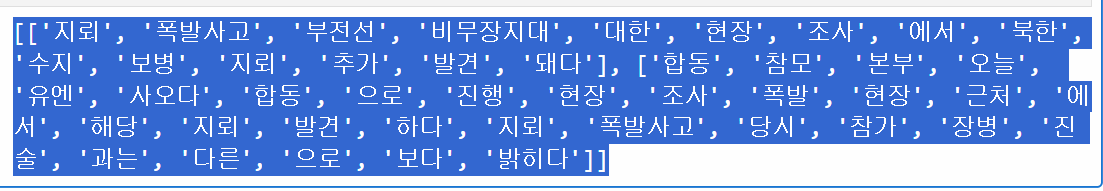

In [37]:
preprocessed_sentences = [['barber', 'kept'],
                          ['barber', 'kept', 'secret'], 
                          ['keeping', 'keeping', 'huge', 'secret', 'driving', 'barber', 'crazy'],
                          ['barber', 'went', 'huge', 'mountain']]

tk = Tokenizer()
tk.fit_on_texts(preprocessed_sentences)

encoded = tk.texts_to_sequences(preprocessed_sentences)
print(f"인코딩 : {encoded}")

print(f"사전 인덱스 : {tk.word_index} ")

max_len = max(len(item) for item in encoded)
print(f"최대 길이 : {max_len}")

인코딩 : [[1, 2], [1, 2, 3], [4, 4, 5, 3, 6, 1, 7], [1, 8, 5, 9]]
사전 인덱스 : {'barber': 1, 'kept': 2, 'secret': 3, 'keeping': 4, 'huge': 5, 'driving': 6, 'crazy': 7, 'went': 8, 'mountain': 9} 
최대 길이 : 7


In [38]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
padded = pad_sequences(encoded, padding='post', maxlen=4, truncating='post')
padded

array([[1, 2, 0, 0],
       [1, 2, 3, 0],
       [4, 4, 5, 3],
       [1, 8, 5, 9]], dtype=int32)

<pre>
array([[1, 2, 0, 0, 0, 0, 0],
       [1, 2, 3, 0, 0, 0, 0],
       [4, 4, 5, 3, 6, 1, 7],
       [1, 8, 5, 9, 0, 0, 0]], dtype=int32)

array([[1, 2, 0, 0],
       [1, 2, 3, 0],
       [3, 6, 1, 7],
       [1, 8, 5, 9]], dtype=int32)

## **원-핫 인코딩(One-Hot Encoding)**

### keras to_categorical()

In [39]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

encoded = [2, 5, 1, 6, 3, 7]
res = to_categorical(encoded)
res

array([[0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1.]])

### pandas get_dummies()

In [40]:
import pandas as pd
res = pd.get_dummies(encoded, dtype='int')
res.values

array([[0, 1, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0],
       [1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0],
       [0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 1]])

### 비추비추 : sklearn OneHotEncoder

In [41]:
from sklearn.preprocessing import OneHotEncoder
import numpy as np
oh = OneHotEncoder()
reshape_encoded = np.array(encoded).reshape(-1, 1)
res = oh.fit_transform(reshape_encoded)
res.toarray()

array([[0., 1., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1.]])

# **[실습] : NLP 전처리**

#### datas/news_sample.txt 파일 읽기

In [42]:
with open("../datas/news_sample.txt", "r", encoding="utf-8") as f:
    content = f.read()
    print(content[:200])

지뢰 폭발사고가 난 서부전선 비무장지대에 대한 3차 현장조사에서 북한의 수지 반보병지뢰 1발이 추가로 발견됐습니다. 합동참모본부는 오늘 유엔사와 합동으로 진행한 현장조사 중 폭발 현장 근처에서 해당 지뢰를 발견했다며, 이 지뢰는 폭발사고 당시 참가한 장병들이 진술한 것과는 다른 것으로 본다고 밝혔습니다.  오늘 현장조사에 투입된 인원은 우리 군 작전병력과 


#### 문장 자르기

In [43]:
from nltk.tokenize import sent_tokenize
sent_list = sent_tokenize(content)
print(sent_list[:2])

['지뢰 폭발사고가 난 서부전선 비무장지대에 대한 3차 현장조사에서 북한의 수지 반보병지뢰 1발이 추가로 발견됐습니다.', '합동참모본부는 오늘 유엔사와 합동으로 진행한 현장조사 중 폭발 현장 근처에서 해당 지뢰를 발견했다며, 이 지뢰는 폭발사고 당시 참가한 장병들이 진술한 것과는 다른 것으로 본다고 밝혔습니다.']


#### 단어 자르기

In [44]:
from nltk.tokenize import word_tokenize
word_list = word_tokenize(content)
print( word_list[:20] )

['지뢰', '폭발사고가', '난', '서부전선', '비무장지대에', '대한', '3차', '현장조사에서', '북한의', '수지', '반보병지뢰', '1발이', '추가로', '발견됐습니다', '.', '합동참모본부는', '오늘', '유엔사와', '합동으로', '진행한']


In [45]:
tot_word_list = []
for sent in sent_list:
   word_list = word_tokenize(sent)
   tot_word_list.extend(word_list) 

print( tot_word_list[:20] )

['지뢰', '폭발사고가', '난', '서부전선', '비무장지대에', '대한', '3차', '현장조사에서', '북한의', '수지', '반보병지뢰', '1발이', '추가로', '발견됐습니다', '.', '합동참모본부는', '오늘', '유엔사와', '합동으로', '진행한']


#### 명사 자르기

In [46]:
from konlpy.tag import Okt
# from konlpy.tag import Kkma
# from konlpy.tag import Komoran
okt     = Okt()
word_list = okt.nouns (content)
print( word_list[:20] )

['지뢰', '폭발사고', '난', '부전선', '비무장지대', '대한', '차', '현장', '조사', '북한', '수지', '보병', '지뢰', '발', '추가', '발견', '합동', '참모', '본부', '오늘']


### 불용어 처리

In [47]:
from sklearn.feature_extraction.text import CountVectorizer

stop_words_list = stopwords.words('korea')
cv = CountVectorizer(stop_words=stop_words_list)

sentense_list = [content]
cv.fit_transform(sentense_list)

#print("불용처리 후 :", cv.get_feature_names_out())

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 193 stored elements and shape (1, 193)>

In [48]:
import re

def MY_TOKENIZER_FUNC(content):
    okt = Okt()
    word_list = okt.morphs(content, stem = True)
    p = re.compile(r'^[a-zA-Z0-9가-힣]{2,}$')
    res = [word for word in word_list if p.match(word)]
    return res
    
stop_words_list = stopwords.words('korea')
cv = CountVectorizer(stop_words=stop_words_list
                , tokenizer=MY_TOKENIZER_FUNC
                #, lowercase=False
                #, token_pattern=r'(?u)\b[a-zA-Z0-9가-힣]{2,}\b'
                #, token_pattern='(?u)\\b\\w\\w+\\b'
               )

sentense_list = [content]
cv.fit_transform(sentense_list)

clean_word_list = cv.get_feature_names_out()
print("불용처리 후 :", clean_word_list)


불용처리 후 : ['10월' '1일' '21일' '29일' '30' 'SNS' '가다' '가족' '가지' '간부' '겪다' '계획' '공개' '과는'
 '관련' '구성' '국감' '국무회의' '국민' '국정감사' '국회' '규명' '근거' '근처' '기관' '깊다' '내다'
 '다치다' '달이' '당국' '당부' '당시' '당일' '대놓고' '대책' '대통령' '대한' '더불다' '덧붙이다' '돼다'
 '되다' '따로' '라며' '리버' '리스터' '마다' '막다' '망신' '멈추다' '메시지' '명령' '무분별' '무제한'
 '묻다' '민생' '민심' '민주당' '발견' '발목' '발생' '발언' '밝히다' '버리다' '법안' '병력' '보다' '보병'
 '본부' '본회의' '부전선' '북한' '비무장지대' '비판' '빠르다' '사고' '사오다' '상정' '상황' '석상' '소모'
 '수지' '수행' '시작' '신속하다' '아니다' '안보' '앞두다' '어려움' '언급' '없다' '에도' '여야' '예고'
 '오늘' '오전' '요구' '원내대표' '위로' '유엔' '음모론' '의결' '의장' '이다' '이라고' '이재명' '인데'
 '인원' '일부' '자제' '작전' '잡기' '장병' '쟁이' '쟁점' '전해지다' '전형' '정기' '정위' '정쟁' '정책'
 '조사' '주기' '주다' '주문' '주재' '증인' '지난주' '지다' '지뢰' '지름길' '지시' '지적' '직후' '진상'
 '진술' '진행' '참가' '참모' '참여' '채택' '처리' '처음' '철저하다' '청와대' '추가' '추석' '토론' '통해'
 '투입' '특히' '파악' '폭발' '폭발사고' '하다' '한다는' '한병도' '합동' '해달라다' '해당' '현장' '협조'
 '회복' '회의']


## 시각화

<pre>
<b>파워쉘 관리자 권한 (한글폰트 설치)</b>
* docker exec -it -u root my_tf_env bash
* apt-get update && apt-get install -y fonts-nanum
* cd /usr/share/fonts/truetype/nanum
    
<b>주피터 터미널 실행</b>
* pip install WordCloud

In [49]:
one_line_text = " ".join(clean_word_list)
one_line_text

'10월 1일 21일 29일 30 SNS 가다 가족 가지 간부 겪다 계획 공개 과는 관련 구성 국감 국무회의 국민 국정감사 국회 규명 근거 근처 기관 깊다 내다 다치다 달이 당국 당부 당시 당일 대놓고 대책 대통령 대한 더불다 덧붙이다 돼다 되다 따로 라며 리버 리스터 마다 막다 망신 멈추다 메시지 명령 무분별 무제한 묻다 민생 민심 민주당 발견 발목 발생 발언 밝히다 버리다 법안 병력 보다 보병 본부 본회의 부전선 북한 비무장지대 비판 빠르다 사고 사오다 상정 상황 석상 소모 수지 수행 시작 신속하다 아니다 안보 앞두다 어려움 언급 없다 에도 여야 예고 오늘 오전 요구 원내대표 위로 유엔 음모론 의결 의장 이다 이라고 이재명 인데 인원 일부 자제 작전 잡기 장병 쟁이 쟁점 전해지다 전형 정기 정위 정쟁 정책 조사 주기 주다 주문 주재 증인 지난주 지다 지뢰 지름길 지시 지적 직후 진상 진술 진행 참가 참모 참여 채택 처리 처음 철저하다 청와대 추가 추석 토론 통해 투입 특히 파악 폭발 폭발사고 하다 한다는 한병도 합동 해달라다 해당 현장 협조 회복 회의'

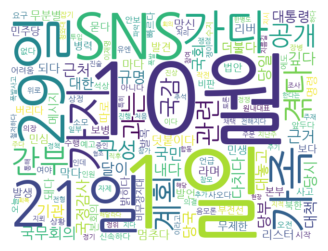

In [50]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf' 

# 워드클라우드 생성
wordcloud = WordCloud(
    font_path=font_path,      # 한글 폰트 지정
    width=640, 
    height=480,               # 워드클라우드 세로 크기
    background_color='white'  # 배경색
).generate(one_line_text)

# 워드클라우드 출력
plt.figure(figsize=(10, 3))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # 축 숨김
plt.show()


## 인코딩/패딩

* **형태소 토큰화, 불용어 처리**

In [51]:
from tensorflow.keras.preprocessing.text import Tokenizer

clean_sent_list = []
okt = Okt()
for sent in sent_list:
    word_list = okt.morphs(sent, stem=True)
    p = re.compile(r'^[a-zA-Z0-9가-힣]{2,}$')
    res = [word for word in word_list if p.match(word)]
    clean_sent_list.append(res)
    
print(clean_sent_list[:2])

[['지뢰', '폭발사고', '부전선', '비무장지대', '대한', '현장', '조사', '에서', '북한', '수지', '보병', '지뢰', '추가', '발견', '돼다'], ['합동', '참모', '본부', '오늘', '유엔', '사오다', '합동', '으로', '진행', '현장', '조사', '폭발', '현장', '근처', '에서', '해당', '지뢰', '발견', '하다', '지뢰', '폭발사고', '당시', '참가', '장병', '진술', '과는', '다른', '으로', '보다', '밝히다']]


In [52]:
tk = Tokenizer()
tk.fit_on_texts(text_list)

#print(f"문장 카운트 : {tk.document_count}") #------ nltk sent_tokenizer()
#print(f"단어 카운트 : {tk.word_counts} ")   #------- python Counter(단어빈도수)
#print(f"사전 인덱스: {tk.word_index}")      #------- 인덱스 사전

encoded = tk.texts_to_sequences(text_list)     #------- 인코딩(문장->숫자 바꾸기)
print(f"인코딩 : {encoded[:2]}")

max_len = max(len(item) for item in encoded)
print(f"최대 길이 : {max_len}")

인코딩 : [[1, 2, 3], [1, 4, 5]]
최대 길이 : 3


In [53]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
padded = pad_sequences(encoded, padding='post', maxlen=28, truncating='post')
padded

array([[1, 2, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0],
       [1, 4, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0],
       [6, 2, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0]], dtype=int32)

# -------------------------------

# **[3] 언어 모델(Language Model)**
* 단어 시퀀스(문장)에 확률을 할당(assign)하는 모델

<img src="https://velog.velcdn.com/images/bluebarry3/post/784117c6-f0fe-4935-b536-925828706a6e/image.png">

## **[3-1] 통계적 언어 모델 : 조건부확률**
* 통계적 언어 모델(Statistical Language Model, SLM)

### 조건부 확률(Conditional Probability)

### N-gram 언어 모델(N-gram Language Model)
* 일부 단어를 몇 개(N) 보느냐 

## **[3-2] 통계적 언어모델 : 카운트기반**
* BoW(Bag of Words)
* DTM(Document Term Matrix)
* TF-IDF(Term Frequency-Inverse Document Frequency)

### BoW : (Bag of Words)
* 단어의 등장 순서를 고려하지 않는 빈도수 기반의 단어 표현 방법
* (1) 각 단어에 고유한 정수 인덱스를 부여합니다.  # 단어 집합 생성.
* (2) 각 인덱스의 위치에 단어 토큰의 등장 횟수를 기록한 벡터를 만듭니다. 

<pre>
text = ["나는 오늘 친구랑 학교에 간다.", 
        "너는 오늘 집에 집에 간다." ]
OrderDict[(나는 1) (오늘 2) (친구랑 1) (학교에 1) (간다 2) (너는 1) (집에 2)]

     {'나는':1  '오늘':2  '친구랑':3  '학교에':4  '간다':5  '너는':6  '집에':7}
문서1 "나는 오늘 친구랑 학교에 간다."  --> [1,2,3,4,5]
문서2 "너는 오늘 집에 집에 간다."      --> [1,2,7,7,5]

     {'나는':1  '오늘':2  '친구랑':1  '학교에':1  '집에':2  '간다':2  '너는':1  }
     {'간다': 0 , '나는': 1, '너는': 2, '오늘': 3,  '집에': 4 , '친구랑': 5, '학교에': 6 } --> 가나다순정렬
문서1     1        1         0          1         0          1        1         
문서2     1        0         1          1         2          0        0        

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

sentense_list = ["나는 오늘 친구랑 학교에 간다.", "너는 오늘 집에 집에 간다." ]
cv = CountVectorizer() #stop_words='english')
bow_array = cv.fit_transform(sentense_list).toarray()

print("단어:"       , cv.get_feature_names_out())
print("단어,인덱스:" , cv.vocabulary_)
print("BoW:"        , bow_array)

단어: ['간다' '나는' '너는' '오늘' '집에' '친구랑' '학교에']
단어,인덱스: {'나는': 1, '오늘': 3, '친구랑': 5, '학교에': 6, '간다': 0, '너는': 2, '집에': 4}
BoW: [[1 1 0 1 0 1 1]
 [1 0 1 1 2 0 0]]


### DTM : 문서 단어 행렬(Document-Term Matrix)
* <font color=red><b>DTM = TF : sklearn .. CountVectorizer</b></font>
* 서로 다른 문서들의 BoW들을 결합한 표현 방법
* BoW  집합체(행렬)  == DTM

<pre>
문서1    [ 1        1         0          1         0          1        1 ]    --> BoW     
문서2    [ 1        0         1          1         2          0        0 ]    --> BoW

DTM = [ [1    1     0     1    0     1   1] , 
        [1    0     1     1    2     0   0]
      ]

In [11]:
from sklearn.feature_extraction.text import CountVectorizer

sentense_list = [ "먹고 싶은 사과",
                  "먹고 싶은 바나나",
                  "길고 노란 바나나 바나나",
                  "저는 과일이 좋아요" ]
cv = CountVectorizer() #stop_words='english')
bow_array = cv.fit_transform(sentense_list).toarray()

print("불용처리 후 단어,인덱스:" , cv.vocabulary_)

vocab_sorted = sorted(cv.vocabulary_ , key = lambda x:x[0], reverse = False)
print(vocab_sorted)
print(bow_array)
# print("불용처리 후 단어:"       , cv.get_feature_names_out())

# ['과일이', '길고', '노란', '먹고', '바나나', '사과', '싶은', '저는', '좋아요']
#  "먹고 싶은 사과", -->  0 0 0 1 0 1 1 0 0    

불용처리 후 단어,인덱스: {'먹고': 3, '싶은': 6, '사과': 5, '바나나': 4, '길고': 1, '노란': 2, '저는': 7, '과일이': 0, '좋아요': 8}
['과일이', '길고', '노란', '먹고', '바나나', '사과', '싶은', '저는', '좋아요']
[[0 0 0 1 0 1 1 0 0]
 [0 0 0 1 1 0 1 0 0]
 [0 1 1 0 2 0 0 0 0]
 [1 0 0 0 0 0 0 1 1]]


In [15]:
import pandas as pd
import numpy as np

dtm = pd.DataFrame(bow_array, columns=[vocab_sorted], index=[sentense_list])
dtm

,과일이,길고,노란,먹고,바나나,사과,싶은,저는,좋아요
먹고 싶은 사과,0,0,0,1,0,1,1,0,0
먹고 싶은 바나나,0,0,0,1,1,0,1,0,0
길고 노란 바나나 바나나,0,1,1,0,2,0,0,0,0
저는 과일이 좋아요,1,0,0,0,0,0,0,1,1


### TF-IDF : (Term Frequency-Inverse Document Frequency)
* <font color=red><b>DTM = TF : sklearn .. CountVectorizer</b></font>
* <font color=red><b>TF-IDF : sklearn .. TfidfVectorizer</b></font>
* (1) tf(d,t) : 특정 문서 d에서의 특정 단어 t의 등장 횟수 =====> DTM
* (2) df(t) : 특정 단어 t가 등장한 문서의 수
* (3) idf(t) : df(t)에 반비례하는 수
    *  $ idf(t) = log(\frac{n}{1+df(t)}) $
* 모든 문서에서 자주 등장하는 단어 :  중요도가 낮다 == TF-IDF 값이 낮다
* 특정 문서에서만 자주 등장하는 단어 :  중요도가 높다  == TF-IDF 값이 크다

In [16]:
sentense_list = [ "먹고 싶은 사과",
                  "먹고 싶은 바나나",
                  "길고 노란 바나나 바나나",
                  "저는 과일이 좋아요" ]

* **원리이해**

In [20]:
N = len(sentense_list)

def tf(d,t) :
    return d.count(t)
    
def idf(t) :
    df_cnt = 0
    for sent in sentense_list:
        if t in sent :
            df_cnt += 1 
    return np.log( N /  (df_cnt + 1) )
            
def tfidf(d, t) :
    return tf(d,t) * idf(t)

* **df(d, t)  ==  DTM**

In [25]:
vocab = ['과일이', '길고', '노란', '먹고', '바나나', '사과', '싶은', '저는', '좋아요']
result = []
for i in range(N) :
    result.append([])
    d = sentense_list[i]           #---------- 문서
    for j in range(len(vocab)) :
        t = vocab[j]               #---------- 단어
        result[-1].append(tf(d,t))
result         

[[0, 0, 0, 1, 0, 1, 1, 0, 0],
 [0, 0, 0, 1, 1, 0, 1, 0, 0],
 [0, 1, 1, 0, 2, 0, 0, 0, 0],
 [1, 0, 0, 0, 0, 0, 0, 1, 1]]

In [27]:
cv = CountVectorizer() #stop_words='english')
bow_array = cv.fit_transform(sentense_list).toarray()
bow_array

array([[0, 0, 0, 1, 0, 1, 1, 0, 0],
       [0, 0, 0, 1, 1, 0, 1, 0, 0],
       [0, 1, 1, 0, 2, 0, 0, 0, 0],
       [1, 0, 0, 0, 0, 0, 0, 1, 1]])

* **idf(t)**

In [29]:
idf_list = []
for j in range(len(vocab)) :
    t = vocab[j] 
    idf_list.append(idf(t))
    
print(idf_list)

[np.float64(0.6931471805599453), np.float64(0.6931471805599453), np.float64(0.6931471805599453), np.float64(0.28768207245178085), np.float64(0.28768207245178085), np.float64(0.6931471805599453), np.float64(0.28768207245178085), np.float64(0.6931471805599453), np.float64(0.6931471805599453)]


* **TF-IDF**

In [32]:
result = []
for i in range(N) :
    result.append([])
    d = sentense_list[i]           #---------- 문서
    for j in range(len(vocab)) :
        t = vocab[j]               #---------- 단어
        result[-1].append(tfidf(d, t))

tfidf_df = pd.DataFrame(result , columns=[vocab], index=[sentense_list])
tfidf_df

,과일이,길고,노란,먹고,바나나,사과,싶은,저는,좋아요
먹고 싶은 사과,0.000000,0.000000,0.000000,0.287682,0.000000,0.693147,0.287682,0.000000,0.000000
먹고 싶은 바나나,0.000000,0.000000,0.000000,0.287682,0.287682,0.000000,0.287682,0.000000,0.000000
길고 노란 바나나 바나나,0.000000,0.693147,0.693147,0.000000,0.575364,0.000000,0.000000,0.000000,0.000000
저는 과일이 좋아요,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.693147,0.693147


In [36]:
sentense_list = [ "먹고 싶은 사과",
                  "먹고 싶은 바나나",
                  "길고 노란 바나나 바나나",
                  "저는 과일이 좋아요" ]

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
tfidf_array = tfidf.fit_transform(sentense_list).toarray()
print(tfidf_array)

print(tfidf.vocabulary_)
vocab = ['과일이', '길고', '노란', '먹고', '바나나', '사과', '싶은', '저는', '좋아요']

tfidf_df = pd.DataFrame(tfidf_array, columns=[vocab], index=[sentense_list])
tfidf_df

[[0.         0.         0.         0.52640543 0.         0.66767854
  0.52640543 0.         0.        ]
 [0.         0.         0.         0.57735027 0.57735027 0.
  0.57735027 0.         0.        ]
 [0.         0.47212003 0.47212003 0.         0.7444497  0.
  0.         0.         0.        ]
 [0.57735027 0.         0.         0.         0.         0.
  0.         0.57735027 0.57735027]]
{'먹고': 3, '싶은': 6, '사과': 5, '바나나': 4, '길고': 1, '노란': 2, '저는': 7, '과일이': 0, '좋아요': 8}


,과일이,길고,노란,먹고,바나나,사과,싶은,저는,좋아요
먹고 싶은 사과,0.00000,0.00000,0.00000,0.526405,0.00000,0.667679,0.526405,0.00000,0.00000
먹고 싶은 바나나,0.00000,0.00000,0.00000,0.577350,0.57735,0.000000,0.577350,0.00000,0.00000
길고 노란 바나나 바나나,0.00000,0.47212,0.47212,0.000000,0.74445,0.000000,0.000000,0.00000,0.00000
저는 과일이 좋아요,0.57735,0.00000,0.00000,0.000000,0.00000,0.000000,0.000000,0.57735,0.57735


### 벡터의 유사도(Vector Similarity)
* 유사도 : 문서들 간에 동일/비슷한 단어가 얼마나 공통적으로 많이 사용되었는지 여부
* 문서 간의 단어들의 차이(유클리드 거리, 코사인 유사도 등) 계산

#### **코사인 유사도(Cosine Similarity)**
* <font color=red><b>sklearn .. cosine_similarity</b></font>
* 1 : 완전히 동일한 문서
* 0 : 아무 관계도 아닌 문서 (90°각)
* -1 : 완전히 반대되는 문서 (180°각)
* $ similarity=cos(Θ)=\frac{A⋅B}{||A||\ ||B||}=\frac{\sum_{i=1}^{n}{A_{i}×B_{i}}}{\sqrt{\sum_{i=1}^{n}(A_{i})^2}×\sqrt{\sum_{i=1}^{n}(B_{i})^2}} $
<img src="https://static.wikidocs.net/images/page/24603/%EC%BD%94%EC%82%AC%EC%9D%B8%EC%9C%A0%EC%82%AC%EB%8F%84.PNG" width=400>

* **원리이해**
<pre>
문서1 : 저는 사과 좋아요
문서2 : 저는 바나나 좋아요
문서3 : 저는 바나나 좋아요 저는 바나나 좋아요    

     바나나	사과	저는	좋아요
문서1	0	1	1	1
문서2	1	0	1	1
문서3	2	0	2	2


In [37]:
import numpy as np
from numpy import dot
from numpy.linalg import norm

def cos_sim(A, B):
  return dot(A, B)/(norm(A)*norm(B))

doc1 = np.array([0,1,1,1])
doc2 = np.array([1,0,1,1])
doc3 = np.array([2,0,2,2])

print('문서 1과 문서2의 유사도 :',cos_sim(doc1, doc2))
print('문서 1과 문서3의 유사도 :',cos_sim(doc1, doc3))
print('문서 2와 문서3의 유사도 :',cos_sim(doc2, doc3))

문서 1과 문서2의 유사도 : 0.6666666666666667
문서 1과 문서3의 유사도 : 0.6666666666666667
문서 2와 문서3의 유사도 : 1.0000000000000002


<pre>문서1 : 저는 사과 좋아요
문서2 : 저는 바나나 좋아요
문서3 : 저는 바나나 좋아요 저는 바나나 좋아요  

In [43]:
from sklearn.metrics.pairwise import cosine_similarity

print('문서 1과 문서2의 유사도 :',cosine_similarity([[0,1,1,1]], [[1,0,1,1]])  )
print('문서 1과 문서3의 유사도 :',cosine_similarity([[0,1,1,1]], [[1,0,1,1]])  )
print('문서 2와 문서3의 유사도 :',cosine_similarity([[1,0,1,1]], [[1,0,1,1]])  )

문서 1과 문서2의 유사도 : [[0.66666667]]
문서 1과 문서3의 유사도 : [[0.66666667]]
문서 2와 문서3의 유사도 : [[1.]]


## **[실습] : 영화 유사도**

lec04_실습_영화유사도__.ipynb 참조

# ---- 이후부터는 lec06_RNN__.ipynb --------

## **[3-3] 신경망 언어 모델**

### RNN(Recurrent Neural Network) : 순환 신경망

### LSTM(Long Short-Term Memory) : 장단기 메모리
* LSTM
* BiLSTM

### GRU(Gated Recurrent Unit) : 게이트 순환 유닛

# **[4] 워드 임베딩(Word Embedding)**
* 워드투벡터(Word2Vec)
* 글로브(GloVe)
* 패스트텍스트(FastText)
* 엘모(Embeddings from Language Model, ELMo)

## 워드투벡터(Word2Vec)

## 글로브(GloVe)

# **[5] 토픽 모델링(Topic Modeling)**

## 잠재 디리클레 할당(Latent Dirichlet Allocation, LDA)
* 추천엔진 : NetFlex

## 모델 기반 추천

# **[실습]**
* 감성분석
* 뉴스분석
* 댓글/리뷰 분석
* 추천엔진
* 텍스트 요약(Text Summarization)
* 챗봇

# --------------------------------

# **허깅페이스 토크나이저(Huggingface Tokenizer)**

# **시퀀스-투-시퀀스(Sequence-to-Sequence, seq2seq)**

# **어텐션 메커니즘 (Attention Mechanism)**

# **트랜스포머(Transformer)**

# **BERT(Bidirectional Encoder Representations from Transformers)**
* BERT
* KoBERT

# **GPT(Generative Pre-trained Transformer)**
* ...

# --------------------------------

# **랭체인을 이용한 RAG**

### LangChain을 이용한 GPT-4 호출하기

### 문서를 적재하는 벡터 DB

## LAG

## Agent

## LangGraph

# **[실습] LangChain + RAG + Agent**
* OpenAI vs. Ollama

# --------------------------------

# Vision + Agent

* 시각화
* OpenCV
* YOLO

## 시각화

## OpenCV

## YOLO

# --------------------------------

# **MLOps**
* Docker : 가상화환경
* Kubernetes : 컨테이너 관리
* 자동화배포 : Airflow / CICD / 형상관리

# --------------------------------

# **파이널 프로젝트**
* 서비스